# Séance 9 — Canevas du projet et préparation de la soutenance

Ce notebook n'est pas un atelier : c'est le **squelette de votre rendu**. Remplacez chaque
section par votre travail. La structure suit l'ordre de la soutenance, ce qui vous évite
de refaire le plan au dernier moment.

---

## Identification

| | |
|---|---|
| Groupe |*Yoan Verdie, Zakaria, Daniil Groupe 1*|
| Sujet | *Bibliotheque* |
| Question traitée | *reprise de la fiche, ou reformulée si vous l'affinez* |
| Date de soutenance | *jour 5, après-midi* |

> **Format.** 15 minutes de présentation, 10 minutes de questions devant un jury unique.
> Les questions sont posées individuellement : chaque membre du groupe doit pouvoir
> répondre sur l'intégralité du travail, y compris les parties qu'il n'a pas présentées.
> **Dépôt du rendu : jour 5, 13 h 30.**

> **Convention de nommage du module.** Le code est écrit en anglais et suit la PEP 8 :
> fonctions et variables en `snake_case`, constantes en `MAJUSCULES`. Les **noms de colonnes**
> restent en français parce qu'ils viennent de la source : renommer les colonnes d'un fichier
> d'entrée est une transformation comme une autre, elle se décide et se documente, elle ne se
> fait pas par réflexe. Vous rencontrerez cette situation partout en entreprise.

In [8]:

import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW_DIR = ROOT / 'data' / 'raw'
PROCESSED_DIR = ROOT / 'data' / 'processed'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

print('Données disponibles :')
for path in sorted(RAW_DIR.glob('*')):
    print(' ', path.name)


# Parquet conserve les types (dates, entiers, catégories) là où le CSV les perd :
# c'est le format à privilégier entre deux étapes d'un pipeline. Repli automatique
# sur le CSV si pyarrow n'est pas installé.
def save_dataset(df, name):
    try:
        path = PROCESSED_DIR / f'{name}.parquet'
        df.to_parquet(path, index=False)
    except ImportError:
        path = PROCESSED_DIR / f'{name}.csv'
        df.to_csv(path, index=False)
        print('(pyarrow absent : repli sur le CSV)')
    print('écrit :', path.name, df.shape)
    return path


def load_dataset(name):
    parquet_path = PROCESSED_DIR / f'{name}.parquet'
    csv_path = PROCESSED_DIR / f'{name}.csv'
    if parquet_path.exists():
        return pd.read_parquet(parquet_path)
    if csv_path.exists():
        return pd.read_csv(csv_path)
    raise FileNotFoundError(f'{name} introuvable : exécutez le notebook précédent')


def dataset_exists(name):
    return ((PROCESSED_DIR / f'{name}.parquet').exists()
            or (PROCESSED_DIR / f'{name}.csv').exists())

Données disponibles :
  capteurs.csv
  clients.csv
  evenements_volumineux.csv
  magasins.csv
  produits.csv
  ventes_brutes.csv
  ventes_extrait.csv
  ventes_extrait.json
  ventes_extrait.xlsx


> **Votre jeu de données vous est fourni.** Chaque groupe reçoit un domaine différent,
> avec ses propres anomalies : les chiffres, les pièges et les décisions à justifier ne
> sont pas les mêmes d'un groupe à l'autre. Comparer vos *méthodes* entre groupes est
> encouragé ; comparer vos *résultats* ne vous mènera nulle part.

> **Aucun sujet ne dit quelles anomalies son jeu contient.** Les trouver est la première
> partie du travail, et la première chose que le jury vérifiera. Commencez par appliquer
> votre `profile_dataframe` du jour 1 : elle a été écrite pour cela.

---
## 1. Contexte (2 min de présentation)

**À renseigner :** l'origine des données, ce qu'elles décrivent, la période couverte, et la
question à laquelle le jeu préparé doit permettre de répondre.

*Votre texte :*
                10 Bibliotheques et un site technique. 2 ans d'emprunts (2023-2024).
                Le jeu préparé doit permettre de suivre l'activité de prêt (volume, durée, retards, pertes)
                par site, par famille d'ouvrages, par segment d'adhérents et dans le temps, et d'alimenter
                un tableau de bord (modèle en étoile lisible par Power BI).

In [9]:
# Chargement de la source brute. Aucun nettoyage à ce stade :
# on montre l'état initial, c'est lui qui donne sa valeur au travail qui suit.

# Indiquez ici le dossier de VOTRE groupe (voir la fiche Sujets de projet).
GROUP_DIR = ROOT / 'data' / 'projets' / 'groupe_01_bibliotheque'   # À ADAPTER

print('Fichiers reçus :')
for path in sorted(GROUP_DIR.glob('*.csv')):
    size_kb = path.stat().st_size / 1024
    print(f'  {path.name:<28} {size_kb:>8.0f} Ko')

# La table principale est la plus volumineuse : les autres sont des référentiels.
# TODO : charger la table de faits et les référentiels, puis afficher un head()

table_fait = pd.read_csv(GROUP_DIR / 'emprunts.csv')
ref_adherents = pd.read_csv(GROUP_DIR / 'adherents.csv')
ref_ouvrages = pd.read_csv(GROUP_DIR / 'ouvrages.csv')
ref_sites = pd.read_csv(GROUP_DIR / 'sites.csv')


print("\n",table_fait.head(1))
print("\n",ref_adherents.head(1))
print("\n",ref_ouvrages.head(1))
print("\n",ref_sites.head(1))


Fichiers reçus :
  adherents.csv                     121 Ko
  emprunts.csv                     1616 Ko
  ouvrages.csv                       24 Ko
  sites.csv                           1 Ko

    id_emprunt date_evenement id_adherent id_ouvrage id_site  duree_pret_jours  nb_prolongations valeur_ouvrage_eur mode_emprunt statut
0  EMP0017141     03/02/2024    ADH01040    OUV0150   SIT10              11.0                 2              10.52    sur_place  rendu

   id_adherent date_creation        segment        ville   age
0    ADH00001    2022-05-10  professionnel  montpellier  57.0

   id_ouvrage   libelle    famille            sous_famille  cout_reference_eur
0    OUV0001  Emp-0001  Famille B  Famille B / variante 2              164.38

   id_site    nom_site  ville         region  capacite
0   SIT01  Site Paris  Paris  Ile-de-France       677


---
## 2. Diagnostic (3 min)

Appliquez votre fonction `profile_dataframe` de la séance 2, puis **quantifiez** chaque
anomalie. Un diagnostic sans chiffre n'est pas un diagnostic.

In [10]:
import sys
sys.path.insert(0, str(ROOT / 'src'))
import pandas as pd

from exploration import profile_dataframe

profile_dataframe(table_fait, name='jeu de donnes')

Nom :  jeu de donnes 

Dimensions :  (20563, 10) 

Taille :  205630 

Lignes strictement dupliquées : 180

--- synthèse par colonne ---
                       type  nb_valeurs_manquantes  taux_en_%  nb_valeurs_distinctes
id_emprunt              str                      0       0.00                  20383
date_evenement          str                    412       2.00                   6820
id_adherent             str                      0       0.00                   2600
id_ouvrage              str                      0       0.00                    421
id_site                 str                      0       0.00                     11
duree_pret_jours    float64                   1841       8.95                     92
nb_prolongations      int64                      0       0.00                      4
valeur_ouvrage_eur      str                      0       0.00                   9917
mode_emprunt            str                      0       0.00                      9
statut        

### Tableau des anomalies

| Anomalie | Colonne | Ampleur | Gravité | Traitement retenu |
|---|---|---|---|---|
| date manquantes | date_evenement | 412 valeurs | grave | drop_row |
| dure pret manquantes | duree_pret_jours  | 1841 valeurs | grave | Vérifier si l’absence correspond à un prêt non terminé avant de décider d’une imputation. |
| Dublons stricts | toute les colonnes | 180 valeurs | grave | drop_duplicated() |
| Variantes de casse et d’espaces | mode_emprunt et statut | 9 modalites | moderèe | uniformiser |
| valeur negatif | min duree pret | -5 jours | grave | supprimer | remplacer |
| valeur improbable | max duree pret | 353 jours | moderèe | analyser la donnè |
| mauvais format des donnès | valeur ouvrage eur en str | toute la colonne | grave | convertir en numerique |

---
## 3. Traitements (5 min — la partie la plus longue de la soutenance)

Pour chaque décision, trois éléments sont attendus : **ce que vous avez fait**, **pourquoi**,
et **quelle alternative vous avez écartée**. Le troisième point est celui qui fait la
différence à l'oral.

In [11]:
# Pipeline de nettoyage et de transformation

import pandas as pd


clean_data = table_fait.copy()
log = {'lignes_initiales': len(clean_data)}


# 1. SUPPRIMER LES DOUBLONS STRICTS
log['doublons_stricts_supprimes'] = int(
    clean_data.duplicated().sum()
)
clean_data = clean_data.drop_duplicates().copy()

# 2. CONVERTIR LES DATES
original_dates = clean_data['date_evenement'].copy()

clean_data['date_evenement'] = pd.to_datetime(
    original_dates,
    format='mixed',
    dayfirst=True,
    errors='coerce',
)

log['dates_invalides'] = int(
    (
        original_dates.notna()
        & clean_data['date_evenement'].isna()
    ).sum()
)

# Choix retenu : supprimer les lignes sans date exploitable. Le mécanisme d'absence reste inconnu.
missing_date = clean_data['date_evenement'].isna()
log['lignes_sans_date_supprimees'] = int(missing_date.sum())
clean_data = clean_data.loc[~missing_date].copy()


# 3. UNIFORMISER LES TEXTES DESCRIPTIFS
for column in ['mode_emprunt', 'statut']:
    normalized = (
        clean_data[column]
        .astype('string')
        .str.strip()
        .str.lower()
    )
    log[column + '_modifications'] = int(
        (clean_data[column] != normalized).fillna(False).sum()
    )

    clean_data[column] = normalized


# 4. CONVERTIR LA VALEUR DES OUVRAGES EN NUMÉRIQUE
# Nettoyer les écritures comme "123,45 EUR" ou "123,45 €".
original_values = clean_data['valeur_ouvrage_eur'].copy()

value_text = (
    original_values
    .astype('string')
    .str.replace('EUR', '', regex=False)
    .str.replace('€', '', regex=False)
    .str.replace('\u00a0', '', regex=False)
    .str.replace('\u202f', '', regex=False)
    .str.replace(' ', '', regex=False)
    .str.replace(',', '.', regex=False)
    .str.strip()
)

clean_data['valeur_ouvrage_eur'] = pd.to_numeric(
    value_text,
    errors='coerce',
)

# Ne pas remplacer les échecs par zéro :
# un prix inconnu ne signifie pas qu'un ouvrage ne vaut rien.
failed_value = (
    original_values.notna()
    & clean_data['valeur_ouvrage_eur'].isna()
)

log['valeurs_ouvrage_non_converties'] = int(failed_value.sum())

print("Exemples de valeurs non converties :")
print(original_values.loc[failed_value].head())


# 5. SUPPRIMER LES DURÉES NÉGATIVES
# Selon la règle retenue, une durée de prêt négative est invalide.
negative_duration = clean_data['duree_pret_jours'] < 0

log['durees_negatives_supprimees'] = int(
    negative_duration.sum()
)

clean_data = clean_data.loc[~negative_duration].copy()


# 6. SIGNALER LES DURÉES MANQUANTES
# On conserve les lignes et on ajoute un indicateur.
# On n'impute pas encore : l'absence peut dépendre du statut du prêt.
clean_data['duree_absente'] = (
    clean_data['duree_pret_jours'].isna()
)

log['durees_manquantes_conservees'] = int(
    clean_data['duree_absente'].sum()
)

# Comparer la proportion de durées absentes selon le statut.
print("\nPourcentage de durées absentes par statut :")
print(
    (
        clean_data.groupby('statut')['duree_absente'].mean()
        * 100
    ).round(2)
)


# 7. SIGNALER LES DURÉES ATYPIQUES SANS LES SUPPRIMER
# Une longue durée peut correspondre à un véritable retard.
# L'IQR sert à sélectionner les valeurs à examiner, pas à prouver une erreur.
q1, q3 = clean_data['duree_pret_jours'].quantile([0.25, 0.75])
upper_bound = q3 + 1.5 * (q3 - q1)

clean_data['duree_atypique'] = (
    clean_data['duree_pret_jours'] > upper_bound
)

log['borne_haute_iqr'] = float(upper_bound)
log['durees_atypiques_conservees'] = int(
    clean_data['duree_atypique'].sum()
)


# 8. RETIRER LES DOUBLONS CRÉÉS PAR LES TRANSFORMATIONS
# Des lignes différentes uniquement par la casse ou le format
# peuvent être devenues identiques.
log['doublons_apres_normalisation'] = int(
    clean_data.duplicated().sum()
)

clean_data = clean_data.drop_duplicates().copy()


# 9. AFFICHER LE BILAN
log['lignes_finales'] = len(clean_data)

print("\nJournal du nettoyage :")
for key, value in log.items():
    print(f'{key:<42} {value}')

display(clean_data.head())


Exemples de valeurs non converties :
Series([], Name: valeur_ouvrage_eur, dtype: str)

Pourcentage de durées absentes par statut :
statut
en_retard    9.15
perdu        8.83
rendu        8.89
Name: duree_absente, dtype: float64

Journal du nettoyage :
lignes_initiales                           20563
doublons_stricts_supprimes                 180
dates_invalides                            0
lignes_sans_date_supprimees                407
mode_emprunt_modifications                 4035
statut_modifications                       3958
valeurs_ouvrage_non_converties             0
durees_negatives_supprimees                32
durees_manquantes_conservees               1779
borne_haute_iqr                            60.0
durees_atypiques_conservees                49
doublons_apres_normalisation               0
lignes_finales                             19944


,id_emprunt,date_evenement,id_adherent,id_ouvrage,id_site,duree_pret_jours,nb_prolongations,valeur_ouvrage_eur,mode_emprunt,statut,duree_absente,duree_atypique
0,EMP0017141,2024-02-03,ADH01040,OUV0150,SIT10,11.0,2,10.52,sur_place,rendu,False,False
1,EMP0001852,2023-03-09,ADH01907,OUV0027,SIT08,44.0,0,90.96,sur_place,rendu,False,False
2,EMP0009961,2023-06-21,ADH00282,OUV0108,SIT99,19.0,3,41.88,reservation_en_ligne,perdu,False,False
3,EMP0008711,2024-03-20,ADH02430,OUV0122,SIT02,17.0,2,45.38,portage,perdu,False,False
4,EMP0006209,2023-10-04,ADH00909,OUV0275,SIT02,24.0,3,12.32,reservation_en_ligne,rendu,False,False


## 3.1. Modèle en étoile, encodage et analyse descriptive

Objectifs :
- construire une table de faits et quatre dimensions ;
- vérifier les clés et les correspondances ;
- encoder les variables catégorielles ;
- étudier les moyennes, médianes, écarts types et évolutions temporelles.





In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def create_dimension(df, key):
    """Retirer les doublons stricts et vérifier la clé primaire."""
    dimension = df.drop_duplicates().copy()

    if dimension[key].isna().any():
        raise ValueError(f"Clé manquante dans {key}")

    if dimension[key].duplicated().any():
        raise ValueError(
            f"Plusieurs lignes différentes pour une même clé {key}. "
            "Vérifiez les attributs avant de choisir une ligne."
        )

    return dimension


dim_adherent = create_dimension(ref_adherents, 'id_adherent')
dim_ouvrage = create_dimension(ref_ouvrages, 'id_ouvrage')
dim_site = create_dimension(ref_sites, 'id_site')

# Une ligne par jour, y compris les jours sans emprunt.
dates = clean_data['date_evenement']

if dates.empty or dates.isna().any():
    raise ValueError("Les dates nettoyées doivent être présentes.")

dim_date = pd.DataFrame({
    'date': pd.date_range(
        dates.min().normalize(),
        dates.max().normalize(),
        freq='D',
    )
})

dim_date['cle_date'] = dim_date['date'].dt.strftime('%Y%m%d').astype(int)
dim_date['annee'] = dim_date['date'].dt.year
dim_date['mois'] = dim_date['date'].dt.month
dim_date['trimestre'] = dim_date['date'].dt.quarter
dim_date['jour_semaine'] = dim_date['date'].dt.dayofweek
dim_date['est_weekend'] = dim_date['jour_semaine'] >= 5

# Table de faits : clés, mesures et caractéristiques de l'emprunt.
fact_emprunts = clean_data[[
    'id_emprunt',
    'id_adherent',
    'id_ouvrage',
    'id_site',
    'duree_pret_jours',
    'nb_prolongations',
    'valeur_ouvrage_eur',
    'mode_emprunt',
    'statut',
]].copy()

fact_emprunts['cle_date'] = (
    clean_data['date_evenement']
    .dt.strftime('%Y%m%d')
    .astype(int)
)

fact_emprunts['duree_absente'] = (
    fact_emprunts['duree_pret_jours'].isna()
)

assert fact_emprunts['id_emprunt'].notna().all()
assert fact_emprunts['id_emprunt'].is_unique, (
    "Plusieurs lignes par emprunt : vérifier le grain de la table."
)

display(fact_emprunts.head())

,id_emprunt,id_adherent,id_ouvrage,id_site,duree_pret_jours,nb_prolongations,valeur_ouvrage_eur,mode_emprunt,statut,cle_date,duree_absente
0,EMP0017141,ADH01040,OUV0150,SIT10,11.0,2,10.52,sur_place,rendu,20240203,False
1,EMP0001852,ADH01907,OUV0027,SIT08,44.0,0,90.96,sur_place,rendu,20230309,False
2,EMP0009961,ADH00282,OUV0108,SIT99,19.0,3,41.88,reservation_en_ligne,perdu,20230621,False
3,EMP0008711,ADH02430,OUV0122,SIT02,17.0,2,45.38,portage,perdu,20240320,False
4,EMP0006209,ADH00909,OUV0275,SIT02,24.0,3,12.32,reservation_en_ligne,rendu,20231004,False


In [25]:
## Dimensions

dimensions = {
    'id_adherent': dim_adherent,
    'id_ouvrage': dim_ouvrage,
    'id_site': dim_site,
    'cle_date': dim_date,
}

for key, dimension in dimensions.items():
    unknown = (
        fact_emprunts[key].isna()
        | ~fact_emprunts[key].isin(dimension[key])
    )

    fact_emprunts[f'{key}_inconnu'] = unknown

    print(
        f"{key} : {unknown.sum()} emprunts sans correspondance "
        f"({unknown.mean():.2%})"
    )

# Table enrichie pour les analyses.
analysis_data = (
    fact_emprunts
    .merge(
        dim_adherent[['id_adherent', 'segment']],
        on='id_adherent',
        how='left',
        validate='many_to_one',
    )
    .merge(
        dim_ouvrage[['id_ouvrage', 'famille']],
        on='id_ouvrage',
        how='left',
        validate='many_to_one',
    )
    .merge(
        dim_site[['id_site', 'nom_site', 'region']],
        on='id_site',
        how='left',
        validate='many_to_one',
    )
    .merge(
        dim_date,
        on='cle_date',
        how='left',
        validate='many_to_one',
    )
)

assert len(analysis_data) == len(fact_emprunts)

category_columns = [
    'mode_emprunt', 'statut', 'segment', 'famille', 'region'
]

for column in category_columns:
    analysis_data[column] = (
        analysis_data[column]
        .astype('string')
        .str.strip()
        .str.lower()
        .replace('', pd.NA)
        .fillna('inconnu')
    )

id_adherent : 0 emprunts sans correspondance (0.00%)
id_ouvrage : 59 emprunts sans correspondance (0.30%)
id_site : 0 emprunts sans correspondance (0.00%)
cle_date : 0 emprunts sans correspondance (0.00%)


In [26]:
## One-Hot encoding

one_hot = pd.get_dummies(
    analysis_data[category_columns],
    prefix_sep='=',
    dtype=int,
)

encoded_data = pd.concat([
    analysis_data[[
        'id_emprunt',
        'duree_pret_jours',
        'nb_prolongations',
        'valeur_ouvrage_eur',
        'duree_absente',
    ]],
    one_hot,
], axis=1)

# Chaque variable catégorielle doit avoir une seule modalité active.
for column in category_columns:
    columns = one_hot.columns.str.startswith(column + '=')
    assert one_hot.loc[:, columns].sum(axis=1).eq(1).all()

print("Nombre de colonnes one-hot :", one_hot.shape[1])
display(encoded_data.head())

Nombre de colonnes one-hot : 25


,id_emprunt,duree_pret_jours,nb_prolongations,valeur_ouvrage_eur,duree_absente,mode_emprunt=portage,mode_emprunt=reservation_en_ligne,mode_emprunt=sur_place,statut=en_retard,statut=perdu,statut=rendu,segment=association,segment=particulier,segment=professionnel,famille=famille a,famille=famille b,famille=famille c,famille=famille d,famille=famille e,famille=inconnu,region=auvergne-rhone-alpes,region=bretagne,region=centre-val de loire,region=grand est,region=hauts-de-france,region=ile-de-france,region=nouvelle-aquitaine,region=occitanie,region=paca,region=pays de la loire
0,EMP0017141,11.0,2,10.52,False,0,0,1,0,0,1,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
1,EMP0001852,44.0,0,90.96,False,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0
2,EMP0009961,19.0,3,41.88,False,0,1,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0
3,EMP0008711,17.0,2,45.38,False,1,0,0,0,1,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0
4,EMP0006209,24.0,3,12.32,False,0,1,0,0,0,1,0,1,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0


In [27]:
## Etude des donnèes

numeric_columns = [
    'duree_pret_jours',
    'nb_prolongations',
    'valeur_ouvrage_eur',
]

statistics = analysis_data[numeric_columns].agg([
    'count', 'mean', 'median', 'std', 'min', 'max'
]).T

statistics.columns = [
    'effectif_connu', 'moyenne', 'mediane',
    'ecart_type', 'minimum', 'maximum',
]

statistics['manquants'] = analysis_data[numeric_columns].isna().sum()
statistics['p90'] = analysis_data[numeric_columns].quantile(0.90)

display(statistics.round(2))


def summarize_by_group(df, group):
    return df.groupby(group, dropna=False).agg(
        nb_emprunts=('id_emprunt', 'size'),
        durees_connues=('duree_pret_jours', 'count'),
        duree_moyenne=('duree_pret_jours', 'mean'),
        duree_mediane=('duree_pret_jours', 'median'),
        duree_ecart_type=('duree_pret_jours', 'std'),
        duree_p90=('duree_pret_jours', lambda s: s.quantile(0.90)),
        durees_absentes_pct=('duree_absente', lambda s: s.mean() * 100),
    ).sort_values('nb_emprunts', ascending=False)


stats_by_site = summarize_by_group(analysis_data, 'id_site')
stats_by_family = summarize_by_group(analysis_data, 'famille')
stats_by_segment = summarize_by_group(analysis_data, 'segment')

print("Statistiques par site")
display(stats_by_site.round(2))

print("Statistiques par famille")
display(stats_by_family.round(2))

print("Statistiques par segment")
display(stats_by_segment.round(2))

,effectif_connu,moyenne,mediane,ecart_type,minimum,maximum,manquants,p90
duree_pret_jours,18165.0,25.06,24.00,16.11,7.00,353.00,1779,39.0
nb_prolongations,19944.0,1.51,2.00,1.12,0.00,3.00,0,3.0
valeur_ouvrage_eur,19944.0,53.14,52.18,28.19,6.02,128.24,0,90.01


Statistiques par site


,nb_emprunts,durees_connues,duree_moyenne,duree_mediane,duree_ecart_type,duree_p90,durees_absentes_pct
id_site,,,,,,,
SIT06,1908,1755,24.77,25.0,10.49,39.0,8.02
SIT02,1852,1686,25.42,24.0,17.81,39.0,8.96
SIT05,1822,1676,25.28,24.0,18.25,39.0,8.01
SIT04,1816,1641,24.89,25.0,13.98,39.0,9.64
SIT01,1815,1661,25.03,24.0,14.43,39.0,8.48
SIT08,1811,1642,25.20,24.0,16.58,39.0,9.33
SIT99,1810,1648,24.92,24.0,17.01,39.0,8.95
SIT07,1802,1650,25.10,24.0,15.12,39.0,8.44
SIT09,1775,1605,24.53,24.0,12.95,39.0,9.58


Statistiques par famille


,nb_emprunts,durees_connues,duree_moyenne,duree_mediane,duree_ecart_type,duree_p90,durees_absentes_pct
famille,,,,,,,
famille d,4058,3729,25.06,24.0,15.75,39.0,8.11
famille a,3989,3625,25.02,24.0,14.86,39.0,9.13
famille b,3960,3625,24.73,24.0,15.19,39.0,8.46
famille c,3949,3586,25.40,24.0,17.98,40.0,9.19
famille e,3929,3550,25.11,24.0,16.66,39.0,9.65
inconnu,59,50,26.02,29.0,11.80,41.1,15.25


Statistiques par segment


,nb_emprunts,durees_connues,duree_moyenne,duree_mediane,duree_ecart_type,duree_p90,durees_absentes_pct
segment,,,,,,,
particulier,10015,9117,25.08,24.0,16.72,39.0,8.97
professionnel,6403,5837,25.10,24.0,15.97,39.0,8.84
association,3526,3211,24.95,24.0,14.52,39.0,8.93


### Journal des décisions

| Décision | Justification | Alternative écartée | Motif du rejet |
|---|---|---|---|
|  |  |  |  |
|  |  |  |  |

**Anticipez.** Le jury choisira deux ou trois lignes de ce tableau et vous demandera de les
défendre. Une justification du type « c'est ce qui est le plus courant » ne tient pas.

---
## 4. Composant PySpark (2 min)

Quelle étape avez-vous portée sur Spark, et **pourquoi celle-là** ? Chiffrez : volume
traité, durée, mémoire. Rappel de la séance 7 : « parce que c'est plus rapide » est une
réponse fausse sur une machine unique.

In [12]:
# Étape PySpark et mesures associées
import time
import psutil
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

# 1. Enregistrer les données nettoyées pour que Spark lise un fichier.
input_path = PROCESSED_DIR / 'emprunts_pour_spark.csv'
clean_data.to_csv(input_path, index=False)

# 2. Démarrer Spark en local.
# Le démarrage est mesuré séparément du traitement.
start = time.perf_counter()

spark = (
    SparkSession.builder
    .master('local[*]')
    .appName('AnalyseEmprunts')
    .getOrCreate()
)

startup_seconds = time.perf_counter() - start


# 3. Lire les données et calculer les indicateurs par site.
start = time.perf_counter()

spark_data = (
    spark.read
    .option('header', True)
    .csv(str(input_path.resolve()))
)

# Le CSV est lu en texte : convertir la durée pour calculer sa moyenne.
spark_data = spark_data.withColumn(
    'duree_pret_jours',
    F.col('duree_pret_jours').cast('double'),
)

# count() déclenche réellement la lecture et compte les lignes.
n_rows = spark_data.count()

summary = (
    spark_data.groupBy('id_site')
    .agg(
        F.count('*').alias('nb_emprunts'),
        F.avg('duree_pret_jours').alias('duree_moyenne_jours'),
    )
    .orderBy('id_site')
)

# Spark calcule à la demande : collect() déclenche l'agrégation.
# On récupère uniquement le petit résumé, pas toutes les données.
results = summary.collect()

processing_seconds = time.perf_counter() - start


# 4. Mesurer la mémoire des processus à la fin du traitement.
# Inclure les processus enfants permet notamment d'inclure Java,
# lorsque Spark l'a démarré comme processus enfant de Python.
process = psutil.Process()
processes = [process] + process.children(recursive=True)

rss_bytes = 0
for item in processes:
    try:
        rss_bytes += item.memory_info().rss
    except (psutil.NoSuchProcess, psutil.AccessDenied):
        pass


# 5. Afficher les résultats et les mesures.
summary_pandas = pd.DataFrame([row.asDict() for row in results])

display(summary_pandas.round(2))

print(f'Lignes traitées : {n_rows}')
print(f'Taille du fichier CSV : {input_path.stat().st_size / 1024**2:.2f} Mo')
print(f'Démarrage Spark : {startup_seconds:.2f} secondes')
print(f'Lecture et calculs : {processing_seconds:.2f} secondes')
print(f'Mémoire RSS cumulée en fin de traitement : {rss_bytes / 1024**2:.2f} Mo')

,id_site,nb_emprunts,duree_moyenne_jours
0,SIT01,1815,25.03
1,SIT02,1852,25.42
2,SIT03,1762,25.35
3,SIT04,1816,24.89
4,SIT05,1822,25.28
5,SIT06,1908,24.77
6,SIT07,1802,25.10
7,SIT08,1811,25.20
8,SIT09,1775,24.53
9,SIT10,1771,25.24


Lignes traitées : 19944
Taille du fichier CSV : 1.89 Mo
Démarrage Spark : 0.01 secondes
Lecture et calculs : 0.84 secondes
Mémoire RSS cumulée en fin de traitement : 644.25 Mo


---
## 5. Résultat (3 min)

Le jeu final, sa structure, les indicateurs, la planche de visualisation, et les limites
que vous assumez. **Énoncer soi-même les limites de son travail est valorisé** : cela
montre que vous savez où il ne faut pas faire confiance à vos données.

Dimensions du jeu final : (19944, 12)

Types des colonnes :
id_emprunt                       str
date_evenement        datetime64[us]
id_adherent                      str
id_ouvrage                       str
id_site                          str
duree_pret_jours             float64
nb_prolongations               int64
valeur_ouvrage_eur           Float64
mode_emprunt                  string
statut                        string
duree_absente                   bool
duree_atypique                  bool
dtype: object

OK — contrôles de cohérence réussis

Valeurs manquantes restantes :
id_emprunt               0
date_evenement           0
id_adherent              0
id_ouvrage               0
id_site                  0
duree_pret_jours      1779
nb_prolongations         0
valeur_ouvrage_eur       0
mode_emprunt             0
statut                   0
duree_absente            0
duree_atypique           0
dtype: int64


,nb_emprunts,nb_adherents,duree_moyenne,duree_mediane,nb_durees_connues
id_site,,,,,
SIT06,1908,1349,24.77,25.0,1755
SIT02,1852,1315,25.42,24.0,1686
SIT05,1822,1315,25.28,24.0,1676
SIT04,1816,1320,24.89,25.0,1641
SIT01,1815,1316,25.03,24.0,1661
SIT08,1811,1302,25.20,24.0,1642
SIT99,1810,1315,24.92,24.0,1648
SIT07,1802,1293,25.10,24.0,1650
SIT09,1775,1302,24.53,24.0,1605


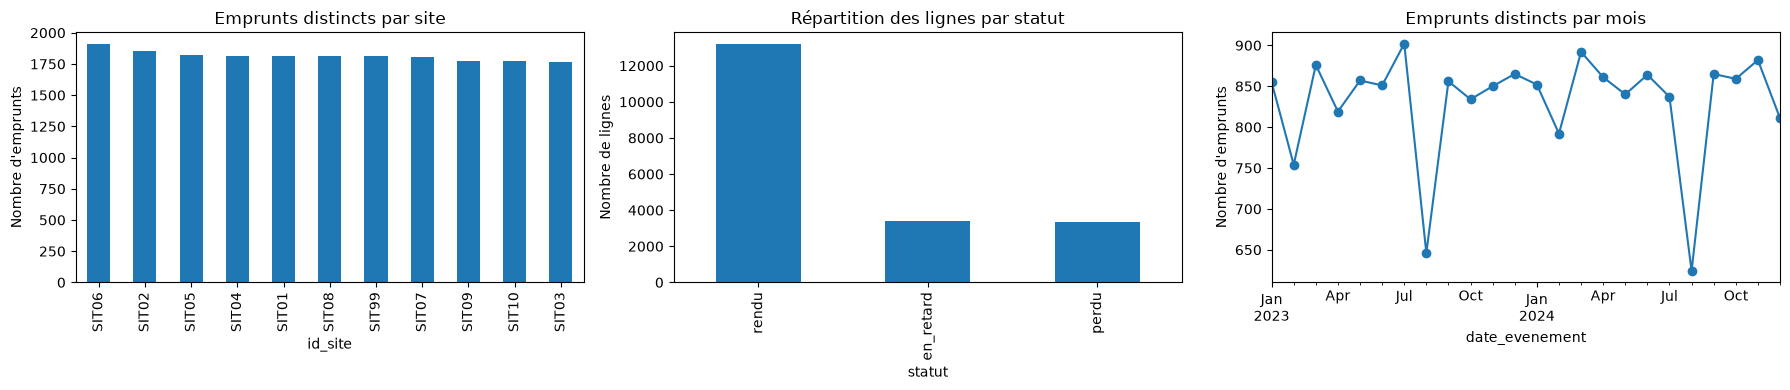

In [13]:
# Chargement du jeu final et contrôles de cohérence

import matplotlib.pyplot as plt

# 1. Définir le jeu final à partir du résultat du nettoyage.
final_data = clean_data.copy()

print("Dimensions du jeu final :", final_data.shape)
print("\nTypes des colonnes :")
print(final_data.dtypes)


# 2. Vérifier les règles appliquées pendant le nettoyage.
# Une assertion arrête le programme si la règle n'est pas respectée.
assert final_data['date_evenement'].notna().all(), "Dates manquantes"
assert not final_data.duplicated().any(), "Doublons stricts présents"

# Les durées manquantes sont autorisées, mais pas les durées négatives.
assert not (
    final_data['duree_pret_jours'] < 0
).any(), "Durées négatives présentes"

print("\nOK — contrôles de cohérence réussis")


# 3. Afficher les valeurs encore manquantes.
# Certaines absences sont conservées volontairement.
print("\nValeurs manquantes restantes :")
print(final_data.isna().sum())


# 4. Construire un tableau d'indicateurs par site.
# Utiliser id_site permet de travailler sans jointure supplémentaire.
indicators = final_data.groupby('id_site').agg(
    nb_emprunts=('id_emprunt', 'nunique'),
    nb_adherents=('id_adherent', 'nunique'),
    duree_moyenne=('duree_pret_jours', 'mean'),
    duree_mediane=('duree_pret_jours', 'median'),
    nb_durees_connues=('duree_pret_jours', 'count'),
)

indicators = indicators.sort_values(
    'nb_emprunts',
    ascending=False,
)

display(indicators.round(2))


# 5. Préparer le nombre d'emprunts distincts par mois.
monthly_loans = (
    final_data
    .set_index('date_evenement')['id_emprunt']
    .resample('MS')
    .nunique()
)


# 6. Créer une planche de trois graphiques.
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

indicators['nb_emprunts'].plot(
    kind='bar',
    ax=axes[0],
    title="Emprunts distincts par site",
)
axes[0].set_ylabel("Nombre d'emprunts")

final_data['statut'].value_counts().plot(
    kind='bar',
    ax=axes[1],
    title="Répartition des lignes par statut",
)
axes[1].set_ylabel("Nombre de lignes")

monthly_loans.plot(
    ax=axes[2],
    marker='o',
    title="Emprunts distincts par mois",
)
axes[2].set_ylabel("Nombre d'emprunts")

plt.tight_layout()
plt.show()

### Limites assumées
Les emprunts sans date et ceux ayant une durée négative ont été exclus : les indicateurs décrivent donc le jeu conservé. Les moyennes et médianes des durées sont calculées uniquement sur les durées renseignées, dont le nombre est affiché. Les durées très élevées restent présentes car elles peuvent correspondre à de vrais retards. Les clés de référence sont contrôlées dans la section 5.2 ; les lignes non appariées restent signalées et conservées. Les durées observées ne suffisent pas à reconstruire un retard sans date limite de retour.

---
## 6. Contrôle avant dépôt

La cellule suivante vérifie que votre rendu est complet. Exécutez-la avant de déposer.

Le dépôt est attendu le **jour 5 à 13 h 30**, avant la reprise de l'après-midi : votre
composant PySpark se termine le matin même. Prévoyez trente minutes pour la mise en forme,
pas cinq.

In [ ]:
checks = {
    'requirements.txt présent': (ROOT / 'requirements.txt').exists(),
    'README.md présent': (ROOT / 'README.md').exists(),
    'dossier src/ non vide': (ROOT / 'src').exists() and any((ROOT / 'src').glob('*.py')),
    'jeu final produit': (any(PROCESSED_DIR.glob('*.parquet'))
                          or any(PROCESSED_DIR.glob('*.csv'))),
    'note méthodologique': any(ROOT.glob('note_methodologique.*')),
    'support de soutenance': any(ROOT.glob('soutenance.*')),
}

width = max(len(label) for label in checks)
for label, is_ok in checks.items():
    print(f"{label:<{width}}  {'OK' if is_ok else 'MANQUANT'}")

if all(checks.values()):
    print('\nRendu complet.')
else:
    print('\nIl manque des éléments listés ci-dessus.')

---
## 7. Préparation aux questions

Rédigez votre réponse à chacune de ces questions **avant** la soutenance. Elles seront
posées dans une formulation proche.

1. Pourquoi avoir imputé cette colonne de cette façon plutôt qu'autrement ?
2. Vous avez écarté un certain pourcentage de lignes. Comment savez-vous qu'il ne
   s'agissait pas d'observations légitimes ?
3. Combien de colonnes votre encodage a-t-il produit ? Quelles conséquences ?
4. À partir de quel volume votre pipeline Pandas cesserait-il de fonctionner ?
5. Si je vous fournis demain un nouveau fichier source au même format, que faut-il faire ?
6. Montrez-moi la ligne de code qui traite ce cas particulier et expliquez-la.
7. Quelle est la principale limite de votre jeu de données final ?

> **Chaque membre du groupe doit pouvoir répondre sur l'intégralité du travail**, y compris
> les parties qu'il n'a pas présentées. Les questions sont posées individuellement.